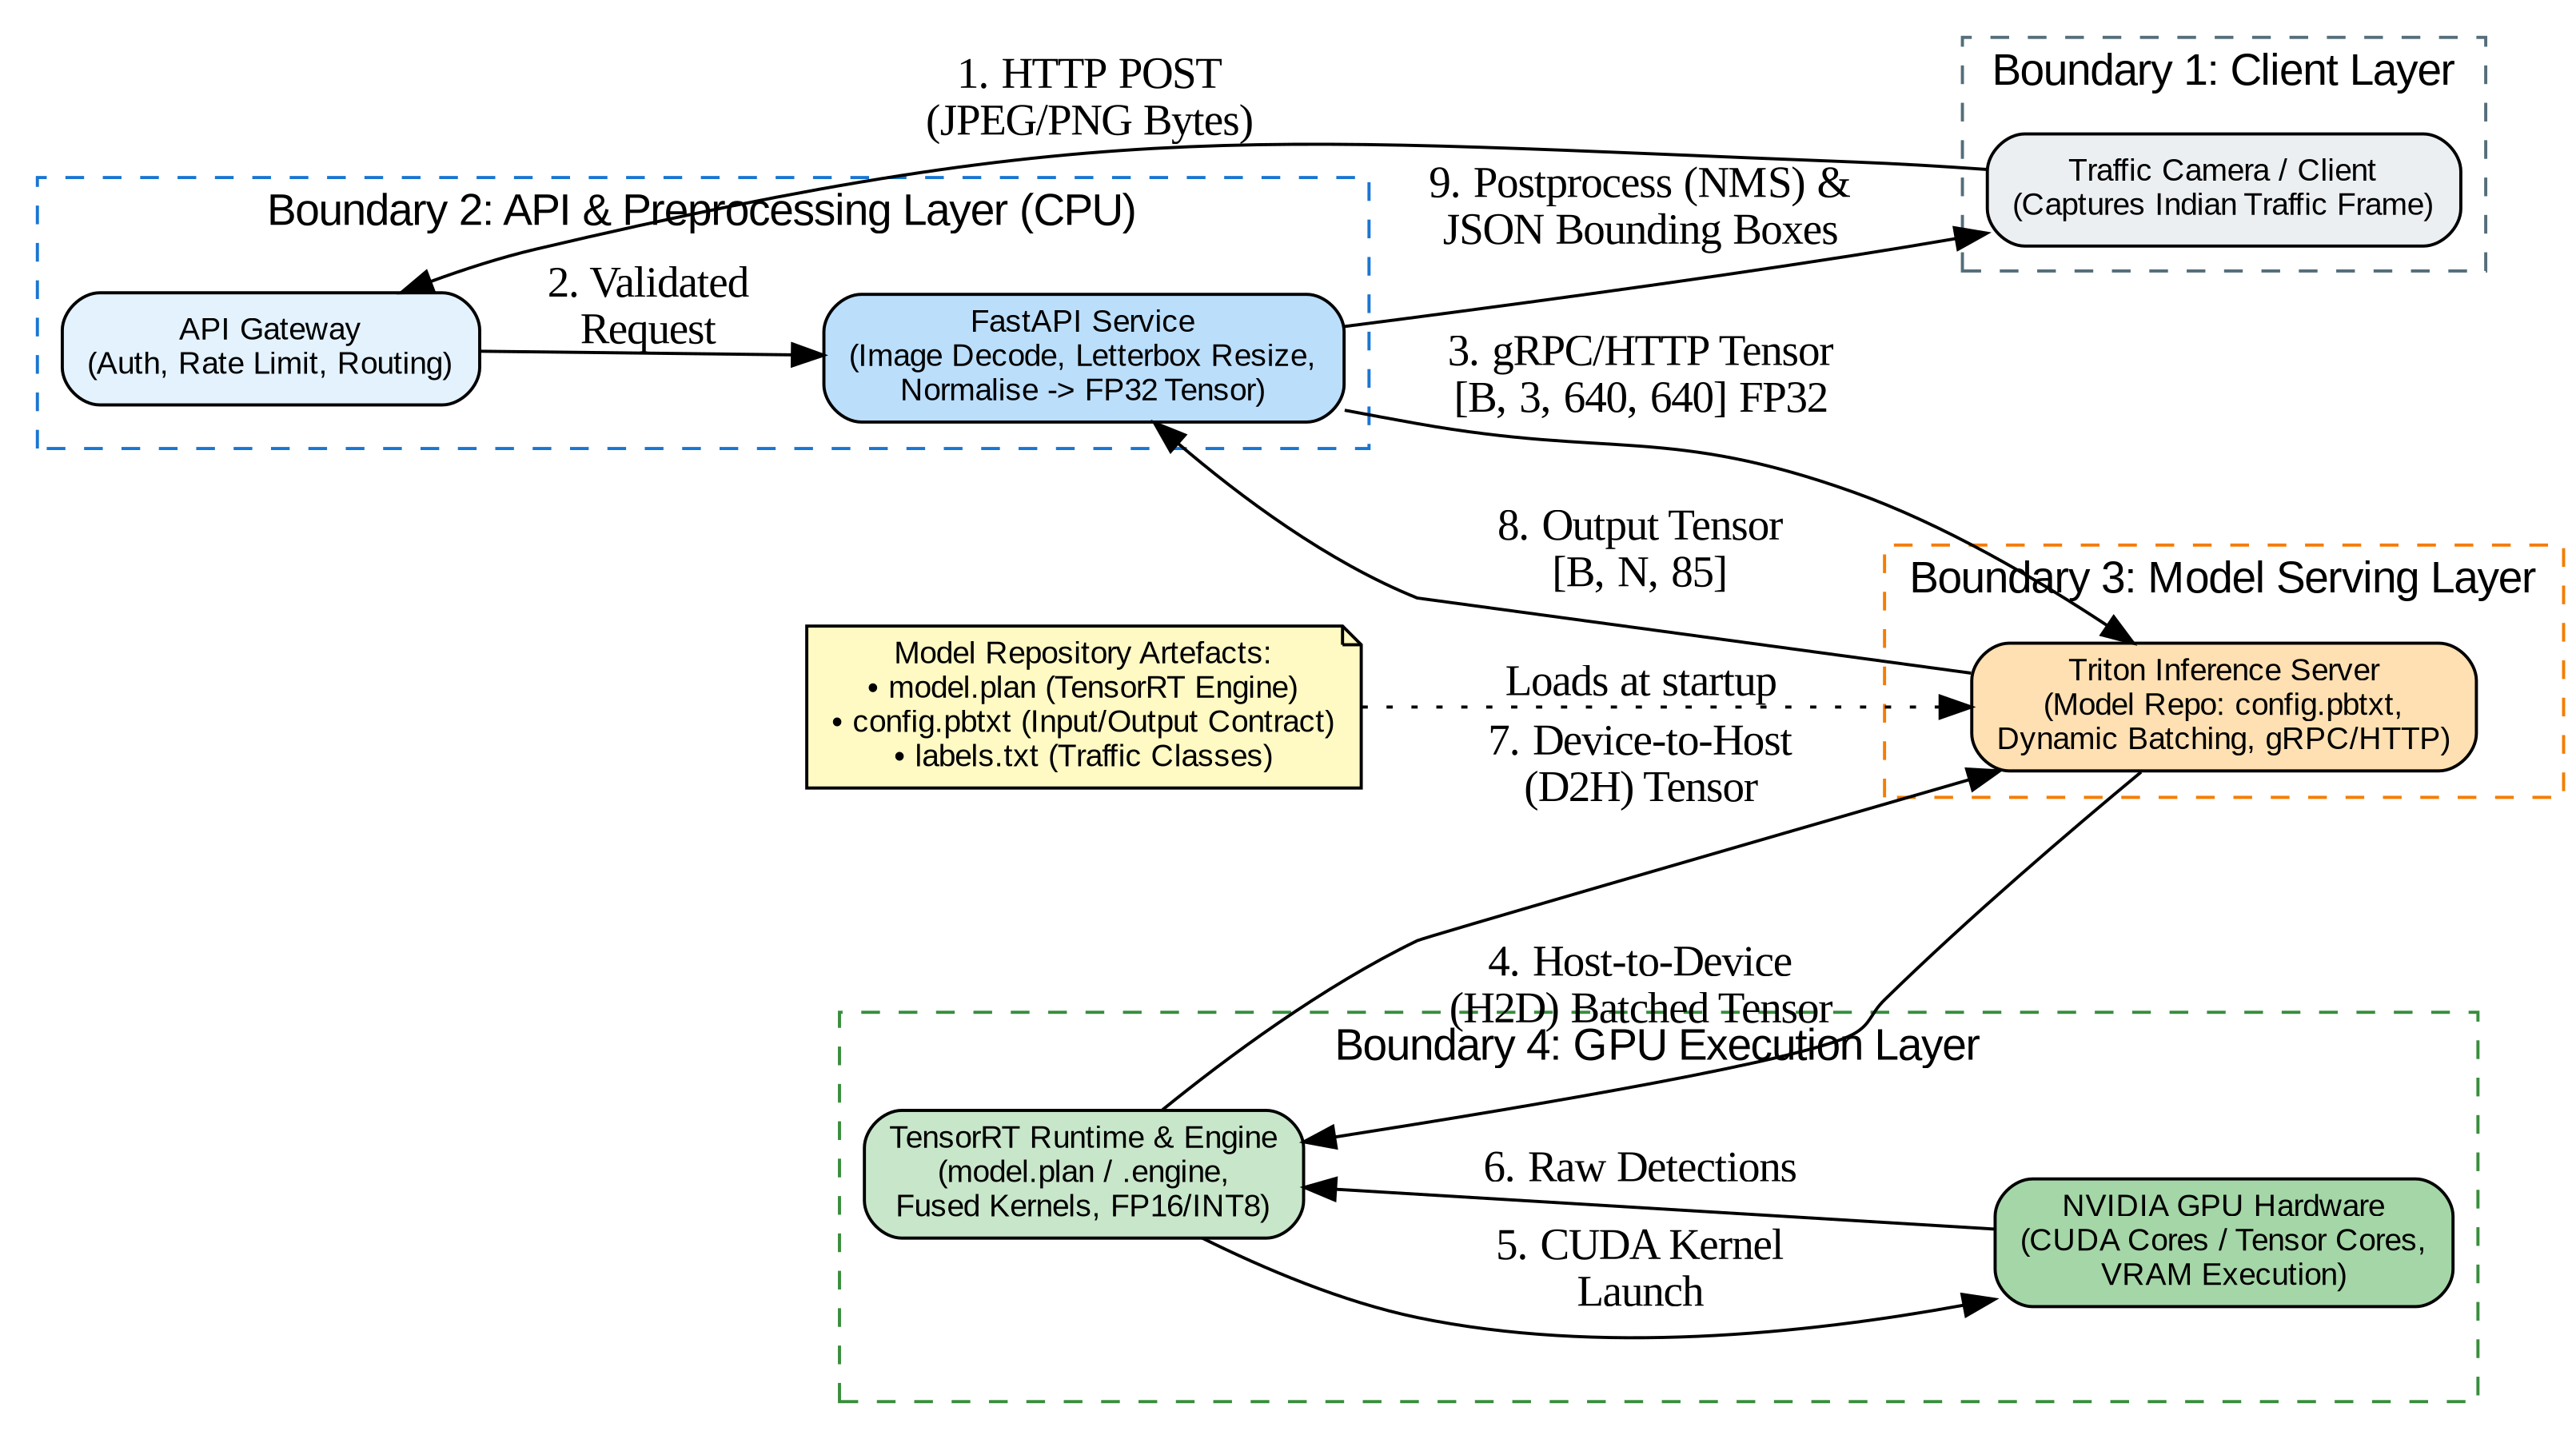


--- VisionPort Inter-Layer Artefact Trace ---
[Boundary 1 -> 2] Client sends JPEG payload: 553449 bytes
[Boundary 2 -> 3] FastAPI sends tensor to Triton: shape=(1, 3, 640, 640), dtype=float32
[Boundary 3 <-> 4] TensorRT returns raw detections: shape=(1, 8400, 10), dtype=float32
[Boundary 2 -> 1] FastAPI returns JSON:
{
  "status": "success",
  "detections": [
    {
      "class": "auto_rickshaw",
      "confidence": 0.92,
      "bbox_xywh": [
        320.0,
        240.0,
        120.0,
        80.0
      ]
    }
  ]
}


In [ ]:
import io
import json
import numpy as np
from PIL import Image as PILImage
from graphviz import Digraph
from IPython.display import Image, display

# ==========================================
# PART 1: Generate Architecture Diagram
# ==========================================
dot = Digraph(comment='VisionPort Serving Architecture', format='png')
dot.attr(rankdir='LR', size='14,6', dpi='300', fontname='Helvetica', compound='true')
dot.attr('node', shape='box', style='rounded,filled', fontname='Helvetica', fontsize='10')

with dot.subgraph(name='cluster_client') as c:
    c.attr(label='Boundary 1: Client Layer', style='dashed', color='#546E7A')
    c.node('CLIENT', 'Traffic Camera / Client\n(Captures Indian Traffic Frame)', fillcolor='#ECEFF1')

with dot.subgraph(name='cluster_api') as c:
    c.attr(label='Boundary 2: API & Preprocessing Layer (CPU)', style='dashed', color='#1976D2')
    c.node('GW', 'API Gateway\n(Auth, Rate Limit, Routing)', fillcolor='#E3F2FD')
    c.node('FAST', 'FastAPI Service\n(Image Decode, Letterbox Resize,\nNormalise -> FP32 Tensor)', fillcolor='#BBDEFB')

with dot.subgraph(name='cluster_triton') as c:
    c.attr(label='Boundary 3: Model Serving Layer', style='dashed', color='#F57C00')
    c.node('TRITON', 'Triton Inference Server\n(Model Repo: config.pbtxt,\nDynamic Batching, gRPC/HTTP)', fillcolor='#FFE0B2')

with dot.subgraph(name='cluster_gpu') as c:
    c.attr(label='Boundary 4: GPU Execution Layer', style='dashed', color='#388E3C')
    c.node('TRT', 'TensorRT Runtime & Engine\n(model.plan / .engine,\nFused Kernels, FP16/INT8)', fillcolor='#C8E6C9')
    c.node('GPU', 'NVIDIA GPU Hardware\n(CUDA Cores / Tensor Cores,\nVRAM Execution)', fillcolor='#A5D6A7')

dot.node('REPO', 'Model Repository Artefacts:\n• model.plan (TensorRT Engine)\n• config.pbtxt (Input/Output Contract)\n• labels.txt (Traffic Classes)', shape='note', fillcolor='#FFF9C4')

dot.edge('CLIENT', 'GW', label=' 1. HTTP POST\n (JPEG/PNG Bytes)')
dot.edge('GW', 'FAST', label=' 2. Validated\n Request')
dot.edge('FAST', 'TRITON', label=' 3. gRPC/HTTP Tensor\n [B, 3, 640, 640] FP32')
dot.edge('TRITON', 'TRT', label=' 4. Host-to-Device\n (H2D) Batched Tensor')
dot.edge('TRT', 'GPU', label=' 5. CUDA Kernel\n Launch')
dot.edge('REPO', 'TRITON', style='dotted', label=' Loads at startup')

dot.edge('GPU', 'TRT', label=' 6. Raw Detections')
dot.edge('TRT', 'TRITON', label=' 7. Device-to-Host\n (D2H) Tensor')
dot.edge('TRITON', 'FAST', label=' 8. Output Tensor\n [B, N, 85]')
dot.edge('FAST', 'CLIENT', label=' 9. Postprocess (NMS) &\n JSON Bounding Boxes')

dot.render('visionport_architecture', cleanup=True)
display(Image('visionport_architecture.png'))

# ==========================================
# PART 2: Simulate Artefact Exchange
# ==========================================
print("\n--- VisionPort Inter-Layer Artefact Trace ---")

# 1. Client -> FastAPI: Raw JPEG bytes
dummy_img = PILImage.fromarray(np.random.randint(0, 255, (720, 1280, 3), dtype=np.uint8))
buf = io.BytesIO()
dummy_img.save(buf, format="JPEG")
http_payload_bytes = buf.getvalue()
print(f"[Boundary 1 -> 2] Client sends JPEG payload: {len(http_payload_bytes)} bytes")

# 2. FastAPI -> Triton: Decoded, letterboxed, normalised FP32 tensor
decoded = PILImage.open(io.BytesIO(http_payload_bytes)).resize((640, 640))
input_tensor = np.transpose(np.asarray(decoded, dtype=np.float32) / 255.0, (2, 0, 1))[None, ...]
print(f"[Boundary 2 -> 3] FastAPI sends tensor to Triton: shape={input_tensor.shape}, dtype={input_tensor.dtype}")

# 3. Triton -> TensorRT/GPU -> Triton: Simulated raw detection tensor [Batch, Boxes, 4+1+Classes]
raw_trt_output = np.zeros((1, 8400, 10), dtype=np.float32)
raw_trt_output[0, 0] = [320.0, 240.0, 120.0, 80.0, 0.92, 0.01, 0.95, 0.01, 0.01, 0.02]
print(f"[Boundary 3 <-> 4] TensorRT returns raw detections: shape={raw_trt_output.shape}, dtype={raw_trt_output.dtype}")

# 4. FastAPI -> Client: Postprocessed JSON response
response_json = json.dumps({
    "status": "success",
    "detections": [{"class": "auto_rickshaw", "confidence": 0.92, "bbox_xywh": [320.0, 240.0, 120.0, 80.0]}]
}, indent=2)
print(f"[Boundary 2 -> 1] FastAPI returns JSON:\n{response_json}")